# Deribit volatility surface vs prediction-market digitals

## Introduction

Polymarket and Kalshi list daily ladders, such as "Will Bitcoin be above \$K at 12:00 ET?". Each strike on the ladder
is a cash-or-nothing digital. Deribit lists BTC and ETH options on the same underlying, and those options carry skew
information that a realized-vol model does not. I wanted to know whether an arbitrage-free surface fitted to Deribit
options could price these ladders better than the venues do.

## Methodology

I first invert Deribit quotes to forward-based Black-76 implied vols, then fit an SSVI surface with no butterfly or
calendar arbitrage. Since the ladders settle between Deribit expiries, I interpolate to the ladder's settlement time in
*variance time* rather than clock time. Finally, I price each strike as $-\partial C/\partial K$, which adds a skew
term to the naive $N(d_2)$.

## Takeaways

The per-expiry SSVI fit lands inside the bid/ask on 70–76% of options, with an RMSE under one vol point. The skew term
is worth 4–7c at the money on a daily ladder, and up to about 13c just below it. In the live run, pricing a daily
digital with the naive $N(d_2)$ was off by about 5c on average.

Against Polymarket's ladder (live run, section 6), the venue sat 2–3c from the surface on average. The largest gaps
were at the money, which is exactly where the USDT/USD basis and the interpolation between expiries matter most.

I parked this work. Deribit's shortest expiry is daily, and the 15-minute and hourly contracts that trade the most
would need its smile extrapolated down to minutes. The realized-vol model in `updown/fair_value.py` is the better tool
there.

The code is in [`updown/surface.py`](../updown/surface.py). Run `python data/fetch.py` first to download a Deribit
snapshot into `data/`. The outputs shown here come from a snapshot taken on 2026-11-07; the raw data is not included.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)
from updown import surface as SF

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9.5, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.precision", 3)

raw = pd.read_parquet(ROOT / "data" / "deribit_options.parquet")
ASOF = pd.Timestamp(raw["ts"].iloc[0])
profile_info = json.loads((ROOT / "data" / "btc_variance_profile.json").read_text())
print(f"Deribit snapshot {ASOF:%Y-%m-%d %H:%M} UTC: "
      + ", ".join(f"{c} {n} options" for c, n in raw.groupby("currency").size().items()))

Deribit snapshot 2026-11-07 11:23 UTC: BTC 930 options, ETH 784 options


## 1. Implied vols

Deribit quotes option premiums in coin, so the USD premium is the coin price times the forward. I invert vols with
Black-76 on each expiry's forward at the bid, ask and mark. Only out-of-the-money options enter the fit, and only if
their vol spread is under 30 points and $|\ln K/F| \le 0.35$. Each option is weighted by the inverse of its spread.

As a sanity check, my inversion should reproduce Deribit's own mark IV.

In [2]:
prep = {c: SF.prepare(raw[raw["currency"] == c], ASOF) for c in ("BTC", "ETH")}
rows = []
for cur, d in prep.items():
    otm = ((d["cp"] == "C") & (d["strike"] >= d["F"])) | ((d["cp"] == "P") & (d["strike"] < d["F"]))
    err = (100 * d.loc[otm, "iv_mark_price"] - d.loc[otm, "mark_iv"]).abs().dropna()
    rows.append({"currency": cur, "OTM options": len(err), "used in fit": int(d["fit"].sum()),
                 "median |IV error| (vol pts)": err.median(), "p90": err.quantile(0.9)})
pd.DataFrame(rows).set_index("currency")

,OTM options,used in fit,median |IV error| (vol pts),p90
currency,,,,
BTC,464,335,0.003,0.018
ETH,391,247,0.004,0.020


## 2. SSVI fit and arbitrage checks

Total implied variance $w = \sigma^2 T$ for each expiry follows the SSVI slice (Gatheral & Jacquier):

$$w(k) = \tfrac{\theta}{2}\left(1 + \rho\varphi k + \sqrt{(\varphi k + \rho)^2 + 1 - \rho^2}\right)$$

where $\theta$ is the ATM total variance. I tested two variants. The first, which I call **slices**, fits one
$(\rho, \varphi)$ per expiry, with $\varphi$ capped at the butterfly-free bound. The second, **global**, fits one $\rho$
and a power-law $\varphi(\theta) = \eta / (\theta^\gamma (1+\theta)^{1-\gamma})$ with $\eta(1+|\rho|) < 2$.

In both variants, $\theta$ is a cumulative sum of positive increments, so it cannot decrease. This rules out calendar
arbitrage by construction. The checks below confirm it on the fitted surface: the butterfly density $g(k) \ge 0$ on
every slice, and no slice crosses the next.

In [3]:
surf = {c: {k: SF.fit_ssvi(prep[c], c, ASOF, k) for k in ("slices", "global")} for c in prep}
rows = []
for cur, fits in surf.items():
    for kind, s in fits.items():
        rows.append({"currency": cur, "fit": kind, "options": s.n, "expiries": len(s.expiries),
                     "RMSE (vol pts)": s.rmse_iv, "inside bid/ask": f"{s.in_spread:.0%}",
                     "min butterfly g": min(SF.butterfly_g(s, i).min() for i in range(len(s.expiries))),
                     "min calendar gap": f"{SF.calendar_gaps(s).min():.1e}"})
pd.DataFrame(rows).set_index(["currency", "fit"])

options  expiries  RMSE (vol pts) inside bid/ask  \
currency fit                                                        
BTC      slices      335        12           0.544            76%   
         global      335        12           0.902            41%   
ETH      slices      247        12           1.014            70%   
         global      247        12           1.992            33%   

                 min butterfly g min calendar gap  
currency fit                                       
BTC      slices            0.250          1.8e-04  
         global            0.256          2.3e-04  
ETH      slices            0.250          2.7e-04  
         global            0.258          4.3e-04

The global fit is about twice as far off, since one $\rho$ cannot follow the skew as it flattens out from the front
expiries to the back. For this reason, everything below uses the per-expiry fit. Its BTC parameters are below.

In [4]:
s = surf["BTC"]["slices"]
pd.DataFrame({"expiry (UTC)": [pd.Timestamp(e).strftime("%Y-%m-%d %H:%M") for e in s.expiries],
              "days": s.T * 365, "forward": s.F, "ATM vol": np.sqrt(s.theta / s.T),
              "rho": s.rho, "phi": s.phi}).round({"days": 2, "forward": 0, "phi": 1})

,expiry (UTC),days,forward,ATM vol,rho,phi
0,2026-11-08 08:00,0.86,75854.0,0.147,-0.134,263.2
1,2026-11-09 08:00,1.86,75863.0,0.215,-0.099,101.8
2,2026-11-10 08:00,2.86,75880.0,0.288,-0.122,48.5
3,2026-11-11 08:00,3.86,75893.0,0.337,-0.183,28.7
4,2026-11-13 08:00,5.86,75918.0,0.357,-0.173,21.9
5,2026-11-20 08:00,12.86,76005.0,0.366,-0.210,12.6
6,2026-11-27 08:00,19.86,76101.0,0.360,-0.195,11.1
7,2026-12-25 08:00,47.86,76428.0,0.374,-0.209,6.6
8,2027-01-29 08:00,82.86,76810.0,0.383,-0.201,4.3
9,2027-03-26 08:00,138.86,77475.0,0.392,-0.190,3.3


## 3. Smiles

The plots below show the four nearest expiries for BTC and ETH. The bars are the bid/ask implied vols of the options
used in the fit, the solid line is the per-expiry fit, and the dashed line is the global fit.

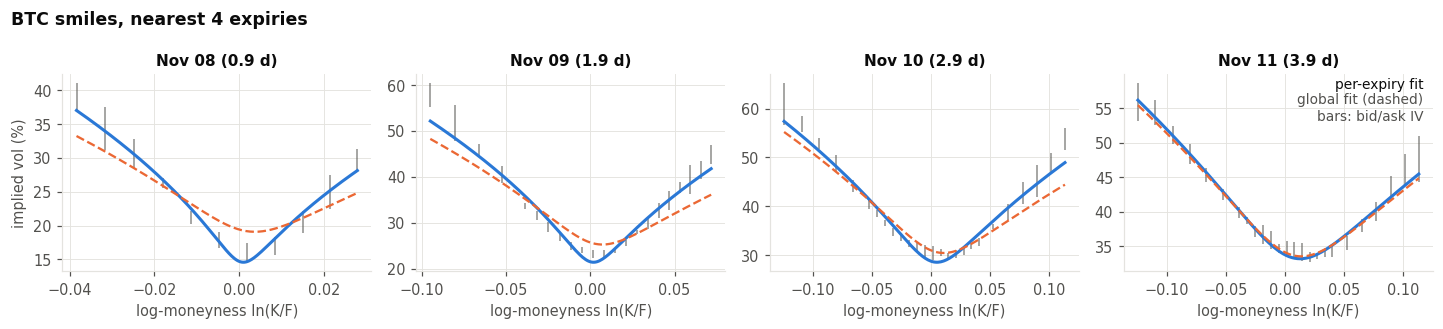

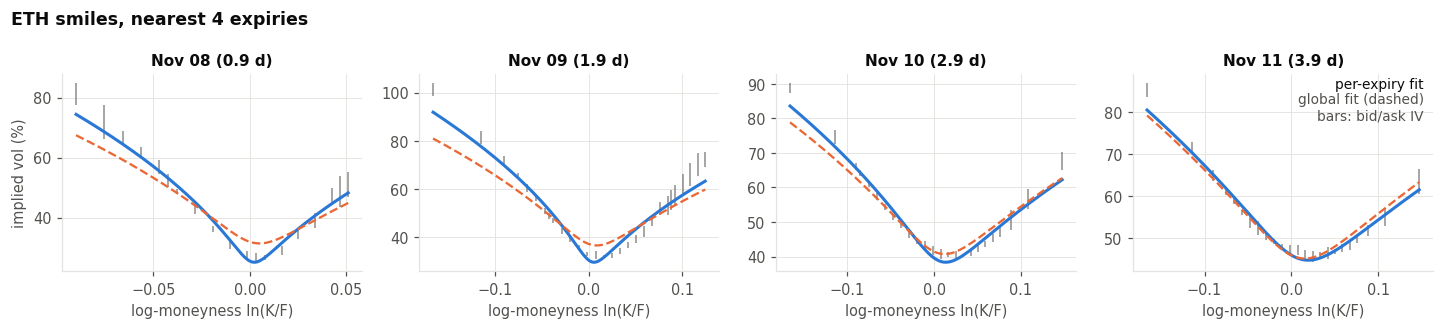

In [5]:
def plot_smiles(cur, n=4):
    d, fits = prep[cur], surf[cur]
    fig, axes = plt.subplots(1, n, figsize=(3.3 * n, 3.0))
    for ax, i in zip(axes, range(n)):
        e = fits["slices"].expiries[i]
        g = d[(d["expiry"] == e) & d["fit"]].sort_values("k")
        ax.vlines(g["k"], 100 * g["iv_bid"], 100 * g["iv_ask"], color=INK2, linewidth=1.2, alpha=0.55)
        kk = np.linspace(g["k"].min(), g["k"].max(), 200)
        T = fits["slices"].T[i]
        ax.plot(kk, 100 * np.sqrt(fits["slices"].w(kk, i) / T), color=BLUE)
        ax.plot(kk, 100 * np.sqrt(fits["global"].w(kk, i) / T), color=ORANGE, linewidth=1.5, linestyle="--")
        ax.set_title(f"{pd.Timestamp(e):%b %d} ({T * 365:.1f} d)")
        ax.set_xlabel("log-moneyness ln(K/F)")
    axes[0].set_ylabel("implied vol (%)")
    a = axes[-1]
    a.annotate("per-expiry fit", xy=(0.97, 0.93), xycoords="axes fraction", ha="right", color=INK, fontsize=9)
    a.annotate("global fit (dashed)", xy=(0.97, 0.85), xycoords="axes fraction", ha="right", color=INK2, fontsize=9)
    a.annotate("bars: bid/ask IV", xy=(0.97, 0.77), xycoords="axes fraction", ha="right", color=INK2, fontsize=9)
    fig.suptitle(f"{cur} smiles, nearest {n} expiries", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()

plot_smiles("BTC")
plot_smiles("ETH")

## 4. Variance time

Deribit's daily options expire at 08:00 UTC, while the ladders settle at 12:00 ET, between two expiries. Splitting the
variance between them by clock hours would treat every hour as equally volatile, which is not the case. Instead, I
interpolate using the intraday variance profile from `fair_value` (weekday/weekend × ET hour, from the last 28 days of
BTC 1-minute returns). In turn, more of the variance lands in the US session.

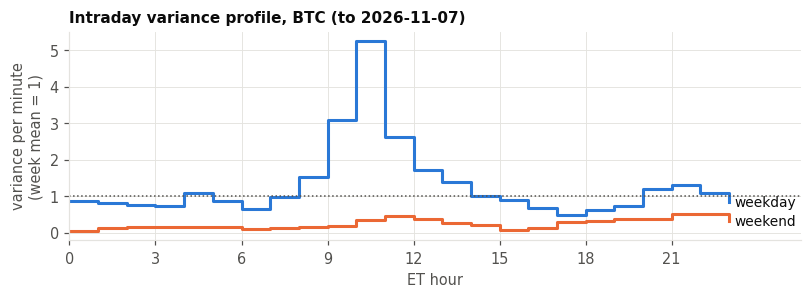

In [6]:
profile = np.array(profile_info["profile"])
CLOCK, FLAT = SF.VarianceClock(profile), SF.VarianceClock.flat()

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.plot(range(24), profile[:24], color=BLUE, drawstyle="steps-post")
ax.plot(range(24), profile[24:], color=ORANGE, drawstyle="steps-post")
ax.axhline(1, color=INK2, linewidth=1, linestyle=":")
ax.text(23.2, profile[23], "weekday", color=INK, va="center", fontsize=9)
ax.text(23.2, profile[47], "weekend", color=INK, va="center", fontsize=9)
ax.set_xlim(0, 25.5); ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("ET hour"); ax.set_ylabel("variance per minute\n(week mean = 1)")
ax.set_title(f"Intraday variance profile, BTC (to {profile_info['profile_date']})", loc="left")
fig.tight_layout()

In [7]:
# first 12:00 ET after the nearest expiry, so the target sits between two fitted expiries
s = surf["BTC"]["slices"]
first = pd.Timestamp(s.expiries[0])
noon = first.tz_convert("America/New_York").normalize() + pd.Timedelta(hours=12)
TARGET = (noon if noon > first else noon + pd.Timedelta(days=1)).tz_convert("UTC")
nxt = pd.Timestamp(s.expiries[1])

share = {name: c.between(first, TARGET) / c.between(first, nxt) for name, c in (("variance clock", CLOCK), ("flat clock", FLAT))}
print(f"target {TARGET.tz_convert('America/New_York'):%a %Y-%m-%d %H:%M} ET, between expiries "
      f"{first:%m-%d %H:%M} and {nxt:%m-%d %H:%M} UTC")
for k, v in share.items():
    print(f"  share of the inter-expiry variance before the target, {k}: {v:.1%}")

target Sun 2026-11-08 12:00 ET, between expiries 11-08 08:00 and 11-09 08:00 UTC
  share of the inter-expiry variance before the target, variance clock: 23.0%
  share of the inter-expiry variance before the target, flat clock: 37.5%


## 5. Digitals with the skew term

A digital is the negative strike-derivative of a call. On a surface where implied vol depends on strike, this adds a
term to the naive Black price:

$$P(S_T > K) = N(d_2) - \varphi(d_2)\,\frac{\partial w / \partial k}{2\sqrt{w}}$$

With negative skew ($\partial w/\partial k < 0$ near the money), the ATM digital sits above $N(d_2)$.

,ATM vol at target,ATM skew term (c),max |skew term| (c),max |variance clock - flat| (c)
currency,,,,
BTC,0.166,3.973,11.045,2.727
ETH,0.259,6.945,13.288,2.279


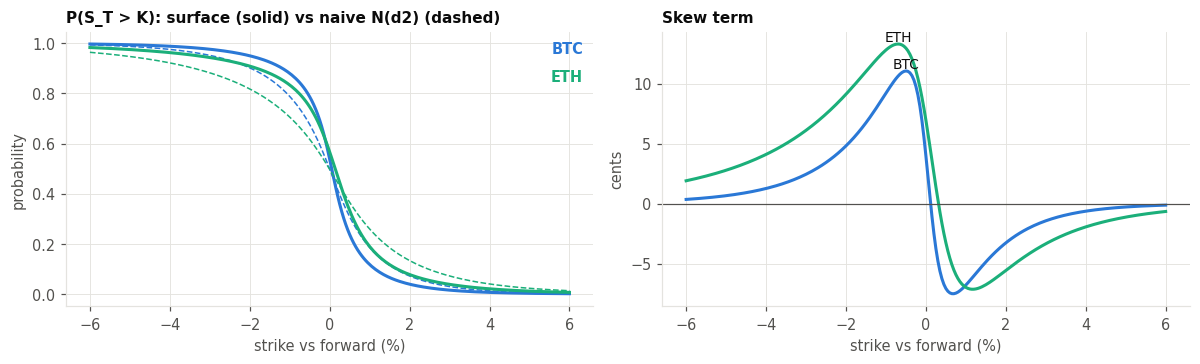

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
summary = []
for cur, col in (("BTC", BLUE), ("ETH", AQUA)):
    s = surf[cur]["slices"]
    F0 = SF.w_at(s, TARGET, [0.0], CLOCK)[2]
    K = F0 * np.exp(np.linspace(-0.06, 0.06, 241))
    dv, df = SF.digitals(s, TARGET, K, CLOCK), SF.digitals(s, TARGET, K, FLAT)
    x = 100 * dv["k"]
    axes[0].plot(x, dv["p"], color=col)
    axes[0].plot(x, dv["naive"], color=col, linewidth=1, linestyle="--")
    axes[1].plot(x, 100 * dv["skew_term"], color=col)
    j = int(np.argmax(dv["skew_term"].abs().to_numpy()))
    axes[1].text(x.iloc[j], 100 * dv["skew_term"].iloc[j] + 0.25, cur, color=INK, ha="center", fontsize=9)
    atm = int(np.argmin(dv["k"].abs().to_numpy()))
    summary.append({"currency": cur, "ATM vol at target": dv["iv"].iloc[atm],
                    "ATM skew term (c)": 100 * dv["skew_term"].iloc[atm],
                    "max |skew term| (c)": 100 * dv["skew_term"].abs().max(),
                    "max |variance clock - flat| (c)": 100 * (dv["p"] - df["p"]).abs().max()})
axes[0].set_title("P(S_T > K): surface (solid) vs naive N(d2) (dashed)", loc="left")
axes[0].set_ylabel("probability"); axes[1].set_ylabel("cents")
axes[1].set_title("Skew term", loc="left")
axes[1].axhline(0, color=INK2, linewidth=0.8)
for a in axes:
    a.set_xlabel("strike vs forward (%)")
axes[0].text(0.98, 0.92, "BTC", color=BLUE, transform=axes[0].transAxes, ha="right", fontweight="bold")
axes[0].text(0.98, 0.82, "ETH", color=AQUA, transform=axes[0].transAxes, ha="right", fontweight="bold")
fig.tight_layout()
pd.DataFrame(summary).set_index("currency")

## 6. Against the venues (live run, 2026-10-29)

The comparison against live ladders needs the venue recorders and market catalog, which are not included in this
repository. The results below are from the original run, using a Deribit snapshot from 2026-10-29 20:46 PT and a ladder
settling at 12:00 ET the next day, 12.2 h ahead.

Polymarket's ladder settles on Binance BTCUSDT, so I mapped strikes to USD at the observed USDT basis (+27.9 bp for
BTC, +23.4 bp for ETH). The `edge` column is the cents per contract from taking the venue's best price against the
surface digital, after the taker fee.

| K | bid | ask | surface | naive N(d2) | edge (c) |
|---|---|---|---|---|---|
| 74,000 | 0.975 | 0.977 | 0.963 | 0.933 | +1.07 |
| 76,000 | 0.892 | 0.894 | 0.892 | 0.825 | −0.70 |
| 78,000 | 0.509 | 0.524 | 0.603 | 0.530 | **+6.12** |
| 80,000 | 0.100 | 0.110 | 0.122 | 0.153 | +0.49 |
| 82,000 | 0.018 | 0.024 | 0.023 | 0.037 | −0.24 |

Exhibit A: Polymarket's BTC ladder against the surface, for strikes away from 0 and 1.

| venue | currency | strikes | mean \|mid − surface\| (c) | mean mid − surface (c) | mean \|naive − surface\| (c) | best edge (c) |
|---|---|---|---|---|---|---|
| Polymarket | BTC | 4 | 2.92 | −2.22 | 5.05 | 6.12 |
| Polymarket | ETH | 3 | 3.01 | −1.59 | 5.40 | 4.11 |

Exhibit B: Summary over strikes priced between 3% and 97%.

A Kalshi hourly event 13 minutes from settlement showed a 3.0c mean |mid − surface| over 8 strikes.

The naive $N(d_2)$ sits further from the surface (5c) than the venue does (3c), which suggests the venue roughly prices
the skew. The one large gap is the ATM strike. This is where a digital is most sensitive to the forward, so a few bp of
USDT basis error, or the 08:00 UTC to 12:00 ET interpolation, can move it by cents. Over the hours I checked, the basis
moved 12–29 bp.

Still, one snapshot is not evidence. The test that matters is whether venue prices converge toward the surface, and who
is right at settlement. That needed the recorded history, which I started collecting but did not run to a verdict.

## 7. Why this was parked

The biggest issue was the horizon. Most of the volume is in 15-minute and hourly contracts, while Deribit's shortest
expiry is daily. Pricing those contracts would mean extrapolating the front smile from hours down to minutes, which is
the least reliable part of the surface. Over 15 minutes, one standard deviation is about 10 bp, so spot and the
settlement-source basis dominate, not the smile.

There was also no clean hedge. An at-the-money digital near expiry has unbounded gamma, and a perp round trip costs 3–4
bp, so I could not turn the surface into a hedged position.

That said, some of this work carried over. The variance clock and the skew-aware digital are general tools, and the
variance-time interpolation reuses the seasonal profile from the realized-vol model. That model is where the project's
pricing work continued.